# Telegram GPT — Learn Kian's conversation style

**Based on the Ferdowsi / Shahnameh `MiniGPT` training notebook.** This experiment **trains a small character-level GPT from scratch**, rather than fine-tuning a pretrained LLM. It is a useful educational baseline. A pretrained multilingual chat model fine-tuned with LoRA will usually be a stronger choice for realistic responses.

### Goal and two roles

- **`Fatemeh`**: the other participant, whose messages provide conversational context.
- **`Kian`**: the target speaker. The model learns to continue conversations **as Kian**.

### Complete pipeline

```text
clean_messages_with_time.json  (or clean_messages.json / conversation.json)
                  |
                  v
          Load + validate records
          map names -> Kian / Fatemeh
                  |
                  v
      Split by inactivity (if timestamps exist)
      Merge consecutive bubbles by speaker
                  |
                  v
      Create supervised Kian reply examples

    CONTEXT                               TARGET
    FATEMEH: سلام خوبی؟\n                 KIAN: خوبم تو چطوری؟\n
                  |
                  v
      Chronological training/validation split
                  |
                  v
     Character vocabulary + integer encoding
                  |
                  v
     PyTorch Dataset with TARGET-ONLY loss mask
                  |
                  v
      GPT Transformer (causal attention)
                  |
                  v
       AdamW training + validation + checkpoint
                  |
                  v
      Give a message from Fatemeh -> reply as Kian
```

**Most important difference from the Shahnameh notebook:** The poetry model predicts *every* next character in its training windows. This model reads both people's text, but **does not calculate loss on the context/prompt characters**. We supervise only the characters of Kian's reply. This is a small, from-scratch example of response-focused supervised learning.

**Privacy:** The source conversation is private. Keep your JSON and saved checkpoints local and do not upload them to public repositories. A trained model can memorize names and exact chat passages. The notebook intentionally avoids printing real messages automatically.

## 1. Environment and configuration

This notebook runs in Jupyter / VS Code or Colab with PyTorch installed. For a local Ubuntu environment:

```bash
pip install torch matplotlib jupyter
```

`DATA_PATH` looks first in your `llm_telegram` project folder, then the notebook's current directory. Prefer `clean_messages_with_time.json` because timestamps let us separate unrelated conversations. The version **without time** also works, but session boundaries are less reliable.

In [ ]:
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass, asdict
from collections import Counter
import json, math, random, time, contextlib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from google.colab import drive

# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. Device and Mixed Precision
# ============================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

USE_AMP = DEVICE == "cuda"

AMP_DTYPE = (
    torch.bfloat16 if torch.cuda.is_bf16_supported()
    else torch.float16
) if USE_AMP else torch.float32


def amp_ctx():
    if USE_AMP:
        return torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE
        )
    return contextlib.nullcontext()


# ============================================================
# 3. Mount Google Drive
# ============================================================

drive.mount("/content/drive")


# ============================================================
# 4. Private Dataset Configuration
# ============================================================

# Your private dataset folder in Google Drive
DATA_DIR = Path("/content/drive/MyDrive/llm_telegram_private")

# Find available Telegram dataset
DATA_CANDIDATES = [
    DATA_DIR / "clean_messages_with_time.json",
    DATA_DIR / "clean_messages.json",
    DATA_DIR / "conversation.json",
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.is_file()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"No Telegram JSON dataset found in {DATA_DIR}\n"
        "Upload clean_messages_with_time.json, "
        "clean_messages.json, or conversation.json to Google Drive."
    )


# ============================================================
# 5. Checkpoint Directory
# ============================================================

# Store trained models privately in Google Drive
CHECKPOINT_DIR = DATA_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 6. Configuration Summary
# ============================================================

print("=" * 50)
print("TELEGRAM GPT - TRAINING CONFIGURATION")
print("=" * 50)

print(f"Dataset:         {DATA_PATH.name}")
print(f"Dataset found:   {DATA_PATH.is_file()}")
print(f"Device:          {DEVICE}")
print(f"GPU:             {torch.cuda.get_device_name(0) if USE_AMP else 'None'}")
print(f"Mixed precision: {AMP_DTYPE if USE_AMP else 'Disabled'}")
print(f"Checkpoints:     {CHECKPOINT_DIR}")
print(f"Random seed:     {SEED}")

print("=" * 50)

Mounted at /content/drive
TELEGRAM GPT - TRAINING CONFIGURATION
Dataset:         clean_messages_with_time.json
Dataset found:   True
Device:          cuda
GPU:             Tesla T4
Mixed precision: torch.bfloat16
Checkpoints:     /content/drive/MyDrive/llm_telegram_private/checkpoints
Random seed:     42


## 2. Load only the two participants

Our input records look like:

```json
{"sender": "Fatemeh", "timestamp": "14.11.2023 18:49:54 UTC+03:30", "text": "سلام"}
```

We ignore Telegram IDs, reply links and any extra fields here. Names are mapped to exactly two roles. We preserve message order, Persian writing, emojis, and informal spelling. We skip non-text messages and empty strings.

**Important:** We need the `sender` value to decide what is *context* and what is *target*. Never remove sender information before role assignment.

In [ ]:
ROLE_ALIASES = {
    "Kian": {"kian", "kian aghmashe", "کیان"},
    "Fatemeh": {"fatemeh", "فاطمه"},
}

def normalize_sender(value):
    if not isinstance(value, str):
        return None
    key = " ".join(value.casefold().split())
    for canonical, aliases in ROLE_ALIASES.items():
        if key in aliases:
            return canonical
    return None

def parse_telegram_timestamp(value):
    if not isinstance(value, str) or not value.strip():
        return None
    try:
        return datetime.strptime(value.strip(), "%d.%m.%Y %H:%M:%S UTC%z")
    except ValueError:
        try:
            return datetime.fromisoformat(value.strip())
        except ValueError:
            return None

def load_messages(path):
    with open(path, "r", encoding="utf-8") as f:
        source = json.load(f)
    rows = source["messages"] if isinstance(source, dict) else source
    if not isinstance(rows, list):
        raise ValueError("Expected a list of messages or {'messages': [...]}")

    messages = []
    dropped = Counter()
    for row in rows:
        if not isinstance(row, dict):
            dropped["not_a_dict"] += 1
            continue
        sender = normalize_sender(row.get("sender"))
        text = row.get("text")
        if sender is None:
            dropped["unknown_sender"] += 1
            continue
        if not isinstance(text, str) or not text.strip():
            dropped["empty_or_nontext"] += 1
            continue
        messages.append({
            "sender": sender,
            "text": text.strip().replace("\r\n", "\n"),
            "time": parse_telegram_timestamp(row.get("timestamp")),
        })
    return messages, dropped

messages, dropped = load_messages(DATA_PATH)
counts = Counter(m["sender"] for m in messages)
print("Valid messages:", len(messages), "| roles:", dict(counts))
print("Dropped:", dict(dropped))
print("With parseable timestamps:", sum(m["time"] is not None for m in messages))
assert counts["Kian"] > 0 and counts["Fatemeh"] > 0, "Both named roles must appear in the data."

Valid messages: 354512 | roles: {'Kian': 154985, 'Fatemeh': 199527}
Dropped: {}
With parseable timestamps: 354512


## 3. Group message bubbles into conversation turns

One person often sends several Telegram bubbles before receiving an answer. Treating each bubble as a complete conversational turn makes training unnatural.

We will:

1. Start a new **session** after an inactivity gap exceeding **2 hours** (only when timestamps are available).
2. Merge consecutive messages from the same sender into one **turn** when the gap is at most **5 minutes**, until the turn reaches a length cap. With no timestamps, consecutive bubbles are merged based on order and the length cap alone.
3. Keep the sessions and turns in original chronological order.

These values are heuristics, not universal truths: adjust them after inspecting your data privately. `↵` later marks an internal line break within a single turn; it is not a new speaker.

In [ ]:
SESSION_GAP_MIN = 120
MERGE_GAP_MIN = 5
MAX_MERGED_TURN_CHARS = 550

def delta_minutes(a, b):
    if a is None or b is None:
        return None
    try:
        return (b - a).total_seconds() / 60
    except TypeError:  # e.g. mixing offset-aware and offset-naive timestamps
        return None

def make_sessions(messages):
    sessions = []
    current = []
    previous_message_time = None

    for m in messages:
        gap = delta_minutes(previous_message_time, m["time"])
        if current and gap is not None and gap > SESSION_GAP_MIN:
            sessions.append(current)
            current = []

        merge_gap = delta_minutes(current[-1]["time"], m["time"]) if current else None
        can_merge = (
            current
            and current[-1]["sender"] == m["sender"]
            and (merge_gap is None or 0 <= merge_gap <= MERGE_GAP_MIN)
            and len(current[-1]["text"]) + len(m["text"]) + 1 <= MAX_MERGED_TURN_CHARS
        )
        if can_merge:
            current[-1]["text"] += "\n" + m["text"]
            current[-1]["time"] = m["time"]
        else:
            current.append(m.copy())
        previous_message_time = m["time"]

    if current:
        sessions.append(current)
    return sessions

sessions = make_sessions(messages)
print("Sessions:", len(sessions))
print("Merged conversational turns:", sum(map(len, sessions)))
print("Turns per session (first five):", [len(s) for s in sessions[:5]])

Sessions: 2364
Merged conversational turns: 149556
Turns per session (first five): [6, 4, 5, 76, 1]


## 4. Split chronologically into training and validation data

We must evaluate on data the model did not train on. If timestamps produced multiple sessions, assign the **last 10% of sessions** to validation. That prevents adjacent messages from a single session being randomly distributed between train and validation.

If there is only one session (common when using `clean_messages.json` without timestamps), we split that conversation by turn order as a fallback. This is less clean because a long real-life conversation may straddle the split. We do **not** shuffle individual messages first.

In [ ]:
def chronological_split(sessions, train_fraction=0.90):
    if len(sessions) >= 2:
        cut = min(len(sessions) - 1, max(1, int(len(sessions) * train_fraction)))
        return sessions[:cut], sessions[cut:]
    if not sessions or len(sessions[0]) < 6:
        raise ValueError("Not enough dialogue turns to create train and validation sets.")
    turns = sessions[0]
    cut = min(len(turns) - 2, max(2, int(len(turns) * train_fraction)))
    return [turns[:cut]], [turns[cut:]]

train_sessions, val_sessions = chronological_split(sessions)
print("Train sessions:", len(train_sessions), "| validation sessions:", len(val_sessions))

Train sessions: 2127 | validation sessions: 237


## 5. Build the supervised examples: **Fatemeh / Kian → Kian**

For every Kian turn immediately following a Fatemeh turn, we construct one example:

```text
PROMPT (read, but do not train the output loss on it):
FATEMEH: سلام چطوری؟
KIAN: خوبم مرسی
FATEMEH: فردا میای دانشگاه؟
KIAN:

TARGET (only these characters contribute to loss):
آره احتمالا\n
```

The input to GPT is the prompt plus the target, shifted for next-character prediction. But we set the target IDs for **prompt characters** to `-100` so `CrossEntropyLoss(ignore_index=-100)` ignores those positions.

This matters: if we trained loss on both speakers, the model would also practice generating Fatemeh's messages, even though the goal is to imitate Kian.

**Context budget:** Since this reuses the small character GPT, we have a maximum number of characters per training sequence (`BLOCK_SIZE=384` below). We keep up to 4 preceding turns, drop older turns first, and trim exceptionally long context. We skip overly long Kian replies rather than silently cutting them and pretending they ended there.

In [ ]:
# Configuration shared by dataset preparation and the model.
BLOCK_SIZE = 384
CONTEXT_TURNS = 4
MAX_TARGET_CHARS = 220
KIAN_PREFIX = "KIAN: "
FATEMEH_PREFIX = "FATEMEH: "

def flat_text(text):
    """Keep wording and emoji, but mark internal line breaks without ending a turn."""
    return text.replace("\n", " ↵ ").strip()

def render_turn(turn):
    prefix = KIAN_PREFIX if turn["sender"] == "Kian" else FATEMEH_PREFIX
    return prefix + flat_text(turn["text"]) + "\n"

def make_prompt(prior_turns, max_prompt_chars):
    """Use the most recent turns; at minimum retain the latest Fatemeh message."""
    if not prior_turns or prior_turns[-1]["sender"] != "Fatemeh":
        return None
    if max_prompt_chars < len(KIAN_PREFIX) + len(FATEMEH_PREFIX) + 2:
        return None

    recent = list(prior_turns[-CONTEXT_TURNS:])
    while len(recent) > 1 and len("".join(render_turn(t) for t in recent)) + len(KIAN_PREFIX) > max_prompt_chars:
        recent.pop(0)

    if len("".join(render_turn(t) for t in recent)) + len(KIAN_PREFIX) > max_prompt_chars:
        # In this branch, only the last Fatemeh turn is left. Trim its content,
        # preserving the speaker label and the newline before KIAN:.
        last = flat_text(recent[-1]["text"])
        budget = max_prompt_chars - len(KIAN_PREFIX) - len(FATEMEH_PREFIX) - 1
        if budget < 1:
            return None
        return FATEMEH_PREFIX + last[-budget:] + "\n" + KIAN_PREFIX

    return "".join(render_turn(t) for t in recent) + KIAN_PREFIX

def create_examples(sessions):
    examples = []
    skipped_long = 0
    for session in sessions:
        for i in range(1, len(session)):
            turn = session[i]
            if turn["sender"] != "Kian" or session[i - 1]["sender"] != "Fatemeh":
                continue
            answer = flat_text(turn["text"]) + "\n"
            if not answer.strip() or len(answer) > MAX_TARGET_CHARS + 1:
                skipped_long += 1
                continue
            # BLOCK_SIZE inputs predict BLOCK_SIZE labels; one extra source char is allowed.
            max_prompt = BLOCK_SIZE + 1 - len(answer)
            prompt = make_prompt(session[:i], max_prompt)
            if prompt is None:
                continue
            assert len(prompt + answer) <= BLOCK_SIZE + 1
            examples.append({"prompt": prompt, "answer": answer})
    return examples, skipped_long

train_examples, skip_train = create_examples(train_sessions)
val_examples, skip_val = create_examples(val_sessions)
print("Training reply examples:", len(train_examples))
print("Validation reply examples:", len(val_examples))
print("Long Kian replies skipped:", skip_train + skip_val)
assert train_examples and val_examples, (
    "No train/validation reply pairs. Check speaker names, timestamps, and split; "
    "you may need to adjust the split or use more messages."
)
# Do not automatically print real examples: they may contain private chat content.

Training reply examples: 62823
Validation reply examples: 6387
Long Kian replies skipped: 425


## 6. Build a character tokenizer

As in the Shahnameh notebook, each character (including Persian letters, punctuation, spaces, and emojis) maps to an integer. This keeps the architecture simple for learning, but is much less efficient than the subword tokenizers used by modern LLMs.

The tokenizer learns its vocabulary **from the training split only**. Characters unseen at training time map to `<UNK>` (ID 1). Padding has ID 0, and cannot contribute to the loss.

For example, a tensor has shape `(384,)` even when the real example is shorter, because we pad it to a fixed length. **Padding targets and prompt targets are both `-100`**, so neither affects the loss.

In [ ]:
class CharTokenizer:
    PAD_ID = 0
    UNK_ID = 1

    def __init__(self, chars):
        self.chars = sorted(set(chars))
        self.stoi = {ch: i + 2 for i, ch in enumerate(self.chars)}
        self.itos = {i + 2: ch for i, ch in enumerate(self.chars)}

    @property
    def vocab_size(self):
        return len(self.chars) + 2

    def encode(self, text):
        return [self.stoi.get(ch, self.UNK_ID) for ch in text]

    def decode(self, ids):
        return "".join(self.itos.get(int(idx), "�") for idx in ids if int(idx) != self.PAD_ID)

vocab_chars = set()
for example in train_examples:
    vocab_chars.update(example["prompt"])
    vocab_chars.update(example["answer"])
tok = CharTokenizer(vocab_chars)
print("Vocabulary size:", tok.vocab_size)

IGNORE_INDEX = -100

class TelegramReplyDataset(Dataset):
    """Each item is a fixed-length (x, y) with loss only on Kian's answer."""
    def __init__(self, examples, tokenizer, block_size):
        self.examples = examples
        self.tok = tokenizer
        self.T = block_size

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        example = self.examples[index]
        prompt, answer = example["prompt"], example["answer"]
        ids = self.tok.encode(prompt + answer)
        assert 2 <= len(ids) <= self.T + 1

        x = torch.full((self.T,), self.tok.PAD_ID, dtype=torch.long)
        y = torch.full((self.T,), IGNORE_INDEX, dtype=torch.long)
        n = len(ids) - 1
        x[:n] = torch.tensor(ids[:-1], dtype=torch.long)
        y[:n] = torch.tensor(ids[1:], dtype=torch.long)

        # At x position len(prompt)-1, the target IS the first Kian answer char.
        # Hence mask exactly the preceding len(prompt)-1 next-char labels.
        y[:len(prompt) - 1] = IGNORE_INDEX
        return x, y

train_ds = TelegramReplyDataset(train_examples, tok, BLOCK_SIZE)
val_ds = TelegramReplyDataset(val_examples, tok, BLOCK_SIZE)

# Minimal unit tests: prompt predictions must be ignored; answer predictions supervised.
x0, y0 = train_ds[0]
prompt_length = len(train_examples[0]["prompt"])
assert torch.all(y0[:prompt_length - 1] == IGNORE_INDEX)
assert y0[prompt_length - 1].item() == tok.encode(train_examples[0]["answer"])[0]
assert int((y0 != IGNORE_INDEX).sum()) == len(train_examples[0]["answer"])
print("Dataset mask test passed | x:", tuple(x0.shape), "| supervised characters:", int((y0 != -100).sum()))

Vocabulary size: 289
Dataset mask test passed | x: (384,) | supervised characters: 68


## 7. DataLoaders and the original GPT-style Transformer

A `DataLoader` batches examples into `(B, T)` integer tensors. A `nn.Embedding` maps character IDs into dense vectors, positional embeddings tell the model where characters occur, and stacked **causal self-attention** blocks use earlier text to predict the next character.

The architecture below directly follows your Ferdowsi `MiniGPT`: `MultiheadAttention → residual + LayerNorm → feed-forward MLP → vocabulary projection`.

**The only essential training-related change inside `forward` is `ignore_index=-100` for loss masking.**

In [ ]:
BATCH_SIZE = 32 if DEVICE == "cuda" else 8
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = BLOCK_SIZE
    n_layer: int = 4
    n_head: int = 4
    d_model: int = 256
    dropout: float = 0.1

class Block(nn.Module):
    """Pre-LN GPT decoder block, as in the Shahnameh model."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = nn.MultiheadAttention(
            cfg.d_model, cfg.n_head, dropout=cfg.dropout, batch_first=True
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.mlp = nn.Sequential(
            nn.Linear(cfg.d_model, 4 * cfg.d_model), nn.GELU(),
            nn.Linear(4 * cfg.d_model, cfg.d_model), nn.Dropout(cfg.dropout),
        )
        self.resid_drop = nn.Dropout(cfg.dropout)

    def forward(self, x, causal_mask):
        h = self.ln1(x)
        attended, _ = self.attn(h, h, h, attn_mask=causal_mask, is_causal=True, need_weights=False)
        x = x + self.resid_drop(attended)
        x = x + self.mlp(self.ln2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        mask = torch.triu(torch.ones(cfg.block_size, cfg.block_size, dtype=torch.bool), diagonal=1)
        self.register_buffer("causal_mask", mask, persistent=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for block in self.blocks:
            x = block(x, self.causal_mask[:T, :T])
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
                ignore_index=IGNORE_INDEX,
            )
        return logits, loss

cfg = GPTConfig(vocab_size=tok.vocab_size)
model = MiniGPT(cfg).to(DEVICE)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
xb, yb = next(iter(train_loader))
with torch.no_grad():
    logits, init_loss = model(xb.to(DEVICE), yb.to(DEVICE))
print("x/y batch:", tuple(xb.shape), tuple(yb.shape))
print("Logits:", tuple(logits.shape), "| initial masked loss:", round(init_loss.item(), 4))

Trainable parameters: 3,331,840
x/y batch: (32, 384) (32, 384)
Logits: (32, 384, 289) | initial masked loss: 5.6745


## 8. Optimize GPT weights using masked next-character cross-entropy

Every step:

1. Fetch a batch of Kian-reply examples.
2. Predict next-character logits for the entire prompt + answer.
3. Evaluate cross-entropy **only** at Kian's answer positions.
4. Backpropagate, clip gradients, and update model parameters with AdamW.
5. Evaluate periodically on held-out later dialogue and save the best checkpoint.

The model still **attends to Fatemeh's messages**: masking the *loss* does not hide the prompt from attention.

`MAX_STEPS` is an educational default; quality depends on corpus size, diversity and compute. Start with `20` steps to validate your environment, then increase it for an actual run.

In [ ]:
# ============================================================
# 1. Training Hyperparameters
# ============================================================

MAX_STEPS = 1200 if DEVICE == "cuda" else 120

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
GRAD_CLIP = 1.0

EVAL_EVERY = 100 if DEVICE == "cuda" else 20
EVAL_BATCHES = 20


# ============================================================
# 2. Checkpoint Configuration (Google Drive)
# ============================================================

# CHECKPOINT_DIR was defined in the previous Colab setup cell
# /content/drive/MyDrive/llm_telegram_private/checkpoints/

OUTPUT_DIR = CHECKPOINT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CKPT_PATH = OUTPUT_DIR / "telegram_kian_gpt_best.pt"


# ============================================================
# 3. Optimizer and Gradient Scaler
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Gradient scaling helps prevent underflow with float16.
# It is unnecessary for bfloat16 and full float32.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(USE_AMP and AMP_DTYPE == torch.float16)
)


# ============================================================
# 4. Evaluation Function
# ============================================================

@torch.no_grad()
def evaluate(model, loader, max_batches=EVAL_BATCHES):
    model.eval()

    weighted_loss = 0.0
    supervised_chars = 0

    for i, (xb, yb) in enumerate(loader):
        if i >= max_batches:
            break

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # Count only characters belonging to Kian's target responses
        count = int((yb != IGNORE_INDEX).sum())

        with amp_ctx():
            _, loss = model(xb, yb)

        weighted_loss += loss.item() * count
        supervised_chars += count

    model.train()

    return weighted_loss / max(1, supervised_chars)


# ============================================================
# 5. Infinite Batch Generator
# ============================================================

def infinite_batches(loader):
    while True:
        yield from loader


# ============================================================
# 6. Training Loop
# ============================================================

history = {
    "step": [],
    "train": [],
    "val": []
}

train_iter = infinite_batches(train_loader)

best_val = math.inf
start = time.time()

for step in range(1, MAX_STEPS + 1):

    # ----------------------
    # Get batch
    # ----------------------
    xb, yb = next(train_iter)

    xb = xb.to(DEVICE)
    yb = yb.to(DEVICE)

    optimizer.zero_grad(set_to_none=True)

    # ----------------------
    # Forward pass
    # ----------------------
    with amp_ctx():
        _, loss = model(xb, yb)

    # ----------------------
    # Backpropagation
    # ----------------------
    scaler.scale(loss).backward()

    scaler.unscale_(optimizer)

    nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    scaler.step(optimizer)
    scaler.update()

    # ----------------------
    # Evaluation
    # ----------------------
    if (
        step == 1
        or step % EVAL_EVERY == 0
        or step == MAX_STEPS
    ):

        train_loss = evaluate(model, train_loader)
        val_loss = evaluate(model, val_loader)

        history["step"].append(step)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        elapsed = (time.time() - start) / 60

        print(
            f"step {step:4d}/{MAX_STEPS} | "
            f"train {train_loss:.3f} | "
            f"val {val_loss:.3f} | "
            f"elapsed {elapsed:.1f} min"
        )

        # ----------------------
        # Save best model to Drive
        # ----------------------
        if val_loss < best_val:

            best_val = val_loss

            torch.save(
                {
                    "model": model.state_dict(),
                    "model_cfg": asdict(cfg),
                    "vocab_chars": tok.chars,
                    "step": step,
                    "val_loss": best_val,
                },
                CKPT_PATH
            )

            print(f"  Best model saved to Google Drive (step {step})")


# ============================================================
# 7. Training Summary
# ============================================================

print("\n" + "=" * 50)
print("TRAINING COMPLETED")
print("=" * 50)

print(f"Best checkpoint: {CKPT_PATH}")
print(f"Best validation loss: {best_val:.4f}")
print(f"Total training time: {(time.time() - start)/60:.2f} minutes")

step    1/1200 | train 4.939 | val 4.935 | elapsed 0.0 min
  Best model saved to Google Drive (step 1)
step  100/1200 | train 2.628 | val 2.613 | elapsed 0.3 min
  Best model saved to Google Drive (step 100)
step  200/1200 | train 2.571 | val 2.558 | elapsed 0.6 min
  Best model saved to Google Drive (step 200)
step  300/1200 | train 2.557 | val 2.531 | elapsed 0.9 min
  Best model saved to Google Drive (step 300)
step  400/1200 | train 2.527 | val 2.529 | elapsed 1.2 min
  Best model saved to Google Drive (step 400)
step  500/1200 | train 2.532 | val 2.523 | elapsed 1.5 min
  Best model saved to Google Drive (step 500)
step  600/1200 | train 2.523 | val 2.516 | elapsed 1.8 min
  Best model saved to Google Drive (step 600)
step  700/1200 | train 2.531 | val 2.511 | elapsed 2.1 min
  Best model saved to Google Drive (step 700)
step  800/1200 | train 2.536 | val 2.505 | elapsed 2.5 min
  Best model saved to Google Drive (step 800)
step  900/1200 | train 2.486 | val 2.506 | elapsed 2.8 mi

## 9. Plot learning curves and reload the best checkpoint

A falling **training loss** means the model is fitting seen replies. A falling **validation loss** suggests better character-level prediction on later, unseen replies. If training loss keeps decreasing but validation loss rises, the model may be memorizing rather than generalizing.

Validation loss measures the *characters of Kian's replies*, not overall conversational realism. For style evaluation, also compare generated responses with withheld real replies and ask human raters whether they sound natural.

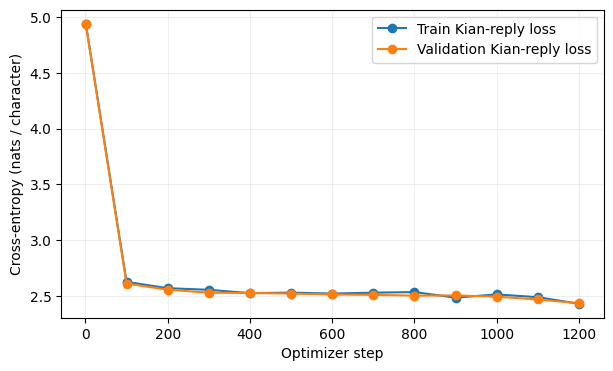

Loaded best model from step: 1200


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history["step"], history["train"], marker="o", label="Train Kian-reply loss")
plt.plot(history["step"], history["val"], marker="o", label="Validation Kian-reply loss")
plt.xlabel("Optimizer step")
plt.ylabel("Cross-entropy (nats / character)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Only load checkpoints you generated yourself or otherwise trust.
checkpoint = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=True)
assert checkpoint["vocab_chars"] == tok.chars
best_model = MiniGPT(GPTConfig(**checkpoint["model_cfg"])).to(DEVICE)
best_model.load_state_dict(checkpoint["model"])
best_model.eval()
print("Loaded best model from step:", checkpoint["step"])

## 10. Generate a reply in Kian's role

At inference time we construct a prompt ending with `KIAN: `, then autoregressively sample one character at a time until the model produces a newline (our turn-ending marker) or reaches `max_chars`.

The function accepts an optional list of prior turns, e.g. `[('Fatemeh', 'سلام'), ('Kian', 'سلام خوبی')]`. Its final `fatemeh_message` argument always adds a new Fatemeh turn.

This is a research demo, **not** an authenticated Telegram bot; review outputs before sharing. The model may memorize sensitive text or generate incoherent answers, especially with limited training.

In [ ]:
@torch.no_grad()
def reply_as_kian(fatemeh_message, history_turns=None, max_chars=160, temperature=0.85, top_k=30):
    if temperature <= 0:
        raise ValueError("temperature must be positive")

    turns = []
    for name, text in (history_turns or []):
        role = normalize_sender(name)
        if role is not None and isinstance(text, str) and text.strip():
            turns.append({"sender": role, "text": text})
    turns.append({"sender": "Fatemeh", "text": fatemeh_message})

    prompt = make_prompt(turns, best_model.cfg.block_size)
    if prompt is None:
        raise ValueError("Could not construct a valid prompt")
    ids = tok.encode(prompt)
    idx = torch.tensor([ids], device=DEVICE, dtype=torch.long)
    result = []
    best_model.eval()

    for _ in range(max_chars):
        with amp_ctx():
            logits, _ = best_model(idx[:, -best_model.cfg.block_size:])
        next_logits = logits[:, -1, :].float() / temperature
        # Avoid generating PAD/UNK characters, which are not valid response text.
        next_logits[:, tok.PAD_ID] = -float("inf")
        next_logits[:, tok.UNK_ID] = -float("inf")
        if top_k is not None:
            k = min(int(top_k), next_logits.size(-1))
            threshold = torch.topk(next_logits, k).values[:, -1, None]
            next_logits[next_logits < threshold] = -float("inf")
        next_id = torch.multinomial(torch.softmax(next_logits, dim=-1), num_samples=1)
        idx = torch.cat((idx, next_id), dim=1)
        ch = tok.decode([int(next_id.item())])
        if ch == "\n":
            break
        result.append(ch)
    return "".join(result).strip()

# Replace this with a prompt of your choice. This is not training data.
test_prompt = "چه خبرا؟"
print("Fatemeh:", test_prompt)
print("Kian (generated):", reply_as_kian(test_prompt))

Fatemeh: چه خبرا؟
Kian (generated): ت دعوایخای به


## 11. How this connects to a pretrained LLM + LoRA

This notebook uses your Ferdowsi model architecture so you can understand the *full* pipeline: constructing conversational examples, masking targets, optimizing a GPT decoder, and generating a response.

However, a small character model trained from scratch has limited language understanding. The stronger next experiment is to **reuse exactly the same reply pairs** but serialize them with a pretrained model's **chat template**:

```json
{"messages": [
  {"role": "user", "content": "فردا دانشگاه میای؟"},
  {"role": "assistant", "content": "آره احتمالا"}
]}
```

Then use a multilingual pretrained model with **supervised fine-tuning (SFT)** and **LoRA/QLoRA**. The pretrained model already knows Persian grammar and general conversation; your dataset primarily teaches it Kian's style. Keep the dataset and model private unless you have the necessary permissions for other people's messages.

**Suggested experiments:** compare (A) from-scratch GPT, (B) pretrained chat model without adaptation, and (C) LoRA-adapted chat model on the same held-out prompts. Evaluate grammaticality, resemblance to Kian's style, memorization, and unwanted disclosure of private messages.